In [1]:
import pandas as pd 

In [2]:
#Reading the dataset 
df = pd.read_excel(r"C:\Users\Nitin\Downloads\dataset (1).xlsx")
df.head()

,title,rating,body
0,Horrible product,1,Very disappointed with the overall performance...
1,Camera quality is not like 48 megapixel,3,Camera quality is low
2,Overall,4,"Got the mobile on the launch date,Battery must..."
3,A big no from me,1,1. It doesn't work with 5.0GHz WiFi frequency....
4,Put your money somewhere else,1,"Not worth buying....faulty software, poor disp..."


In [3]:
df.shape  #checked dataset shape 

(1440, 3)

In [4]:
df.info()  #check data info 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1440 entries, 0 to 1439
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   title   1440 non-null   object
 1   rating  1440 non-null   int64 
 2   body    1440 non-null   object
dtypes: int64(1), object(2)
memory usage: 33.9+ KB


In [5]:
df.columns  #columns name in dataset 

Index(['title', 'rating', 'body'], dtype='object')

In [6]:
df.isnull().sum()  # checking is there any null value in dataset 

title     0
rating    0
body      0
dtype: int64

In [7]:
df[df.duplicated()]   #checking duplicate data in dataset 

,title,rating,body


In [8]:
df['Text']= df['title'].fillna(" " )+df['body'].fillna("  " )   
df.drop(columns = ['title','body'],inplace = True )

In [9]:
df.head()

,rating,Text
0,1,Horrible productVery disappointed with the ove...
1,3,Camera quality is not like 48 megapixelCamera ...
2,4,"OverallGot the mobile on the launch date,Batte..."
3,1,A big no from me1. It doesn't work with 5.0GHz...
4,1,Put your money somewhere elseNot worth buying....


In [10]:
def get_sentiment(rating): 
    if rating >3:
        return("Positive")
    elif rating ==3:
        return("Neutral")
    else :
         return("Negative")


df["Sentiment"] = df["rating"].apply(get_sentiment)
df.head()

,rating,Text,Sentiment
0,1,Horrible productVery disappointed with the ove...,Negative
1,3,Camera quality is not like 48 megapixelCamera ...,Neutral
2,4,"OverallGot the mobile on the launch date,Batte...",Positive
3,1,A big no from me1. It doesn't work with 5.0GHz...,Negative
4,1,Put your money somewhere elseNot worth buying....,Negative


In [11]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

nltk.download('stopwords', quiet=True)

True

In [12]:
pip install stopwordsiso

Note: you may need to restart the kernel to use updated packages.


In [13]:
import nltk


nltk.download('stopwords')
nltk.download('punkt_tab')

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

stop_words_eng = set(stopwords.words('english'))
stop_words_eng.difference_update({"no", "not", "never"})

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Nitin\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Nitin\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [14]:
from bs4 import BeautifulSoup 
import re 

In [15]:
def decontracted(text):
    text = re.sub(r"won't", "will not", text)
    text = re.sub(r"can't", "can not", text)
    text = re.sub(r"n't", " not", text)
    text = re.sub(r"'re", " are", text)
    text = re.sub(r"'s", " is", text)
    text = re.sub(r"'d", " would", text)
    text = re.sub(r"'ll", " will", text)
    text = re.sub(r"'ve", " have", text)
    text = re.sub(r"'m", " am", text)
    return text

In [16]:
from tqdm import tqdm

In [17]:
def preprocess_reviews_text(document):
    sentance = re.sub(r"http\S+", "", document)

    sentance = BeautifulSoup(sentance, 'lxml').get_text()

    sentance = decontracted(sentance)

    sentance = re.sub(r"\S*\d\S*", "", sentance).strip()

    sentance = re.sub(r"[^A-Za-z]+", " ", sentance)

    # Removing Special Characters
    text = re.sub(r"[^a-zA-Z0-9\s]", "", sentance)

    text = re.sub(r"(https|http)?\:\/\/.*[\r\n]*", "", text,
                  flags=re.MULTILINE)

    # Remove new line characters
    text = re.sub(r"\n\s*", " ", text)

    # Remove distracting single quotes
    text = re.sub(r"\'", "", text)

    # Remove punctuation marks and other symbols
    text = re.sub(r"[^\w\s-]", " ", text)

    # Removing stopwords
    text = " ".join(
        e.lower() for e in text.split()
        if e.lower() not in stop_words_eng
    )

    cleaned_article = text.strip()

    return cleaned_article

all_reviews = df['Text'][:1440].tolist()

# using tqdm for progress bar
final_reviews = list(map(preprocess_reviews_text, tqdm(all_reviews )))

final_reviews[:5]

100%|████████████████████████████████████████████████████████████████████████████| 1440/1440 [00:00<00:00, 2431.37it/s]


['horrible productvery disappointed overall performance samsung',
 'camera quality not like megapixelcamera quality low',
 'overallgot mobile launch date battery must appreciatedcamera averagemobile performance refresh rate u r buying mobile feature afraid u may get disappointed normal usb cable small lengthit good mobile budget no returns replacement available hence choose wisely buying',
 'big no not work wifi frequency old camera quality pathetic front back forget pictures blur poorer amazon not allow write review sold stock something no return policy live phone not like decide',
 'put money somewhere elsenot worth buying faulty software poor display quality single band wifi not support wifi band gyro sensor missing many dont go paid reviews tube']

In [18]:
df["Clean_Data"] = df['Text'].apply(preprocess_reviews_text)
df

,rating,Text,Sentiment,Clean_Data
0,1,Horrible productVery disappointed with the ove...,Negative,horrible productvery disappointed overall perf...
1,3,Camera quality is not like 48 megapixelCamera ...,Neutral,camera quality not like megapixelcamera qualit...
2,4,"OverallGot the mobile on the launch date,Batte...",Positive,overallgot mobile launch date battery must app...
3,1,A big no from me1. It doesn't work with 5.0GHz...,Negative,big no not work wifi frequency old camera qual...
4,1,Put your money somewhere elseNot worth buying....,Negative,put money somewhere elsenot worth buying fault...
...,...,...,...,...
1435,5,Excellent mobileExcellent mobile,Positive,excellent mobileexcellent mobile
1436,1,Never expected from samsungAll over mobile per...,Negative,never expected samsungall mobile performance p...
1437,5,Good value for moneyBattery life is good but c...,Positive,good value moneybattery life good camera clari...
1438,1,Unreal and whitish displayIt's a very bad prod...,Negative,unreal whitish displayit bad product highly di...


In [19]:
df["Clean_Data"].str.split().str.len().sum()

np.int64(48416)

In [56]:
df["Text"].str.split().str.len().sum()

np.int64(82451)

In [57]:
df.columns

Index(['rating', 'Text', 'Sentiment', 'Clean_Data', 'sentiment_encoded',
       'sentimen', 'sentiment'],
      dtype='object')

In [58]:
X = df['Clean_Data']
y = df['Sentiment']

In [77]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
y_train =  le.fit_transform(y_train)
y_test = le.transform(y_test)

In [78]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20, random_state=42, stratify=y)
print("Training Data",X_train.shape)
print("Testing Data",X_test.shape)

Training Data (1152,)
Testing Data (288,)


In [79]:
from sklearn.feature_extraction.text import TfidfVectorizer
# Create TF-IDF Vectorizer
tfidf= TfidfVectorizer(max_features=5000,ngram_range=(1,2),min_df = 2)

# Learn vocabulary
tfidf.fit_transform(X_train,y_train)

# See first 10 features #GET_FEATURES-NAMES-OUT 
print("Unique words in data corpus:",
      tfidf.get_feature_names_out()[0:5])

print("=" * 50)

# Transform text into TF-IDF vectors
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf =  tfidf.transform(X_test)


print("The shape of our X_train_tfidf vectorizer:", X_train_tfidf.get_shape())
print("The shape of our X_test_tfidf vectorizer:", X_test_tfidf.get_shape())
print("The number of unique words including both unigrams and bigrams:",
      X_train_tfidf.get_shape()[1])

Unique words in data corpus: ['aap' 'able' 'able find' 'able hear' 'able return']
The shape of our X_train_tfidf vectorizer: (1152, 5000)
The shape of our X_test_tfidf vectorizer: (288, 5000)
The number of unique words including both unigrams and bigrams: 5000


In [80]:
# importing models 
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report,precision_score,recall_score,confusion_matrix, ConfusionMatrixDisplay

In [81]:
# Logistic Regression Algorithm
for i in [0.01,0.1,1,10,100,1000,]:
    lr = LogisticRegression(C =i,class_weight="balanced",random_state=0)
    lr.fit(X_train_tfidf,y_train)
    y_pred = lr.predict(X_test_tfidf)
    accu = accuracy_score(y_test,y_pred)*float(100)
    print(f"The Accuracy of LR with C = {i} is {accu}")

The Accuracy of LR with C = 0.01 is 73.95833333333334
The Accuracy of LR with C = 0.1 is 74.65277777777779
The Accuracy of LR with C = 1 is 76.04166666666666
The Accuracy of LR with C = 10 is 76.38888888888889
The Accuracy of LR with C = 100 is 76.73611111111111
The Accuracy of LR with C = 1000 is 77.77777777777779


In [82]:
#Random Forest Algorithm
Rf = RandomForestClassifier(n_estimators=100,class_weight="balanced",random_state=42)
Rf.fit(X_train_tfidf,y_train)
y_pred = Rf.predict(X_test_tfidf)
accu = accuracy_score(y_test,y_pred)*float(100)
print(f"The Accuracy of Random Forest is = {accu}")

The Accuracy of Random Forest is = 75.34722222222221


In [83]:
#Naive Bayes 
Nb = MultinomialNB()
Nb.fit(X_train_tfidf,y_train)
y_pred = Nb.predict(X_test_tfidf)
accu = accuracy_score(y_test,y_pred)*float(100)
print(f"The Accuracy of Naive Bayes  is = {accu}") 

The Accuracy of Naive Bayes  is = 76.73611111111111


In [84]:
#Linear SVC 
for i in [0.01,0.1,1,10,100,1000]:
    svm = LinearSVC(C =i,class_weight="balanced",max_iter=20000,random_state=0)
    svm.fit(X_train_tfidf,y_train)
    y_pred = svm.predict(X_test_tfidf)
    accu = accuracy_score(y_test,y_pred)*float(100)
    print(f"The Accuracy of SVM with C = {i} is {accu}")

The Accuracy of SVM with C = 0.01 is 76.38888888888889
The Accuracy of SVM with C = 0.1 is 79.16666666666666
The Accuracy of SVM with C = 1 is 77.08333333333334
The Accuracy of SVM with C = 10 is 76.38888888888889
The Accuracy of SVM with C = 100 is 75.69444444444444
The Accuracy of SVM with C = 1000 is 75.34722222222221


In [85]:
svm  = LinearSVC(C =0.1,class_weight="balanced",max_iter=20000,random_state=0)
svm.fit(X_train_tfidf,y_train)
y_pred = svm.predict(X_test_tfidf)

In [86]:
#Re Run all models at best Hyperparameter 
models = {
"Logistic Regression": LogisticRegression(C=1,class_weight="balanced",random_state=0),
"Random Forest":RandomForestClassifier(n_estimators=100,class_weight="balanced",random_state=42),
"Naive Bayes": MultinomialNB(),
"SVM":LinearSVC(C =0.1,class_weight="balanced",max_iter=20000,random_state=0)
}

In [87]:
# Preparing common dataframe for comparison 
results = []

for name, model in models.items():
    model.fit(X_train_tfidf, y_train)

    y_pred = model.predict(X_test_tfidf)

    accuracy = accuracy_score(y_test ,y_pred)
    precision = precision_score(y_test, y_pred,average="weighted",zero_division=0)
    recall = recall_score(y_test, y_pred,average="weighted",zero_division=0)
    f1 = f1_score(y_test, y_pred,average="weighted",zero_division=0)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

result_df = pd.DataFrame(results)
result_df

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.760417,0.747059,0.760417,0.753281
1,Random Forest,0.753472,0.650486,0.753472,0.697769
2,Naive Bayes,0.767361,0.666401,0.767361,0.708144
3,SVM,0.791667,0.756803,0.791667,0.762941


In [88]:
#Classification Report 

for name, model in models.items():

    y_pred = model.predict(X_test_tfidf)

    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)
    print(classification_report(y_test,y_pred,zero_division=0))


Logistic Regression
              precision    recall  f1-score   support

    Negative       0.78      0.80      0.79       102
     Neutral       0.27      0.23      0.25        40
    Positive       0.85      0.88      0.86       146

    accuracy                           0.76       288
   macro avg       0.64      0.64      0.63       288
weighted avg       0.75      0.76      0.75       288


Random Forest
              precision    recall  f1-score   support

    Negative       0.74      0.80      0.77       102
     Neutral       0.00      0.00      0.00        40
    Positive       0.77      0.92      0.84       146

    accuracy                           0.75       288
   macro avg       0.50      0.58      0.54       288
weighted avg       0.65      0.75      0.70       288


Naive Bayes
              precision    recall  f1-score   support

    Negative       0.82      0.76      0.79       102
     Neutral       0.00      0.00      0.00        40
    Positive       0.74   

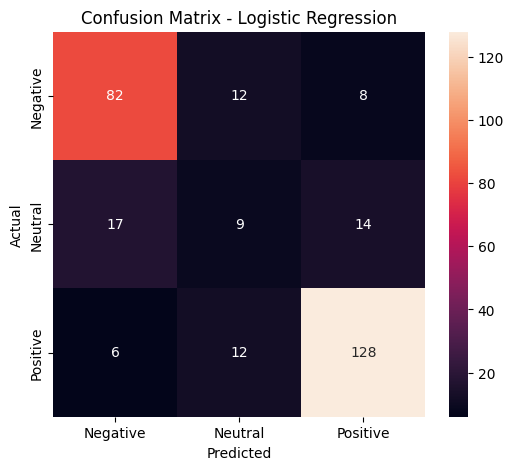

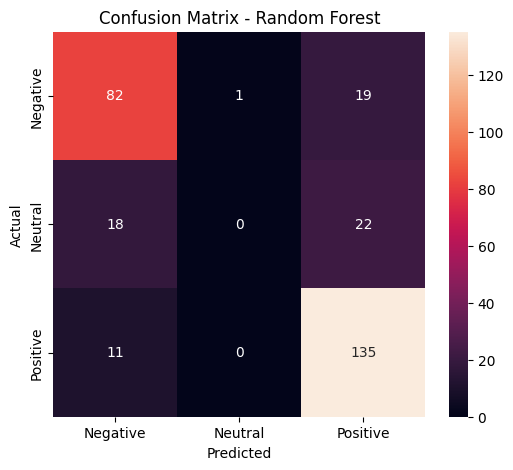

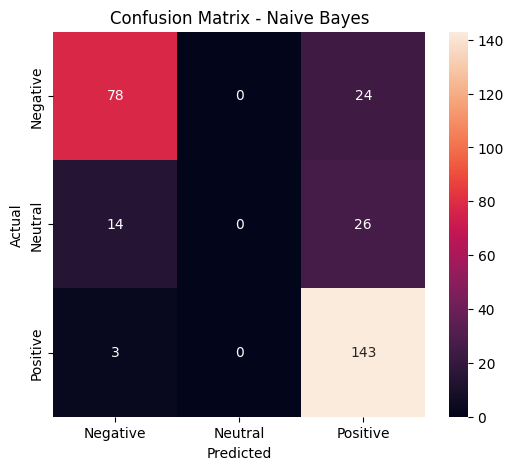

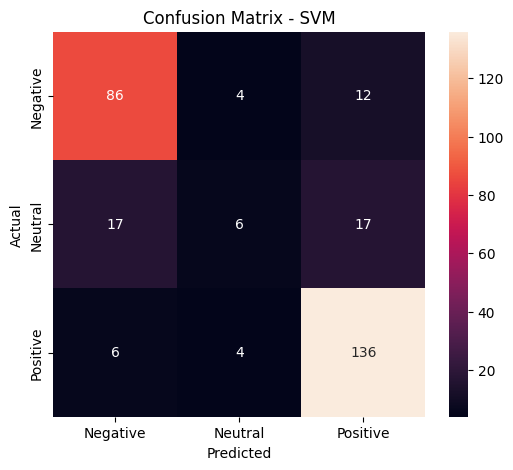

In [89]:
import matplotlib.pyplot as plt 
import seaborn as sns
for name, model in models.items():

    y_pred = model.predict(X_test_tfidf)

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=["Negative", "Neutral", "Positive"]
    )

    plt.figure(figsize=(6, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        xticklabels=["Negative", "Neutral", "Positive"],
        yticklabels=["Negative", "Neutral", "Positive"]
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

In [90]:
import joblib

In [92]:
joblib.dump(model, "SVM.pkl")
joblib.dump(tfidf, "Tfidf.pkl")
joblib.dump(le, "Le.pkl")

print("Model and vectorizer saved successfully.")


Model and vectorizer saved successfully.


In [74]:
import sys
import numpy as np
import sklearn
import joblib

print("Python:", sys.version)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Joblib:", joblib.__version__)

Python: 3.13.9 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 19:09:58) [MSC v.1929 64 bit (AMD64)]
NumPy: 2.3.5
Scikit-learn: 1.7.2
Joblib: 1.5.2
